# GVH Diagonal Cubic — CHH-INVERSE-01 : Hidden Planet Recovery
**Audit reproductible / N-body newtonien / expérience synthétique pseudo-aveugle**  
Version : 2026-11-18 — `GVH_CHH_INVERSE_01_Hidden_Planet_Recovery_FAST`

## Contrat méthodologique gelé AVANT le calcul

- **CHH** = composition de sous-cubes hétérogènes ; ce n'est ni une dérivation d'une planète à partir d'une autre ni une loi de gravitation.
- **Dynamique directe** = gravitation newtonienne standard des masses ponctuelles ; aucune EOM GVH, aucun paramètre $S_{\rm cand}$.
- **Inférence inverse** = estimation d'un corps occulté pour expliquer les trajectoires de trois corps connus.
- Les constantes gravitationnelles $GM$ du Soleil, Jupiter, Saturne, Uranus et Neptune proviennent de JPL ; **les positions et vitesses initiales sont synthétiques** (orbites quasi circulaires planes, phases prescrites). **CE NE SONT PAS les éphémérides JPL** et ce notebook ne reconstruit pas la découverte historique de 1846.
- Vérité cachée **accessible au générateur** ; les routines d'ajustement ne reçoivent que les positions bruitées du Soleil/Jupiter/Saturne/Uranus, pas l'état ni la masse du corps caché. Il s'agit d'un **pseudo-aveugle interne**, non d'un jeu d'observations réellement indépendantes.
- **Entraînement** : $t=0\ldots72$ ans (25 dates). **Test réservé** : $t=74\ldots112$ ans (13 dates). Référence temporelle unique : année julienne de 365,25 jours.
- Bruit synthétique isotrope indépendant, $\sigma=1.5\times10^{-5}$ au par coordonnée, graine fixée `20261118` ; aucune donnée de Neptune incluse dans les observables.
- Modèle inverse **restrictif** : un corps additionnel en orbite initialement circulaire, coplanaire, paramétré par $(GM_X,r_X,\theta_X)$, **trois paramètres estimés**. Un résultat favorable est conditionnel à cette hypothèse.
- Comparaisons pré-définies : **sans corps caché**, puis **sans corps caché en réajustant 4 conditions initiales d'Uranus**. Mesurer séparément les erreurs d'entraînement et de test.
- Critères du benchmark synthétique : (i) RMSE test du meilleur modèle avec corps inférieur à RMSE des deux contrôles ; (ii) rapport des erreurs test >5 par rapport au meilleur contrôle ; (iii) estimation des paramètres à moins de 25 % pour $GM_X$, 5 % pour $r_X$, 0,10 rad pour la phase. Ces tolérances ne sont **pas** des seuils de découverte astronomique.
- Une seconde expérience sans corps caché sert de contrôle négatif. Aucun réglage des seuils après lecture des résultats.

**Références officielles :**  
- JPL, *Astrodynamic Parameters* : https://ssd.jpl.nasa.gov/astro_par.html  
- JPL, *Planetary Discovery Circumstances* : https://ssd.jpl.nasa.gov/planets/discovery.html  
- JPL, *Planetary Ephemerides* : https://ssd.jpl.nasa.gov/planets/eph_export.html

In [1]:
import numpy as np
from scipy.integrate import solve_ivp
from scipy.optimize import least_squares
import hashlib, json, math
from pathlib import Path
import matplotlib.pyplot as plt
np.set_printoptions(precision=8, suppress=True)

AU_M = 149597870700.0  # IAU; cited JPL
YEAR_S = 365.25 * 86400.0
CONV = YEAR_S**2 / AU_M**3  # (m^3/s^2) -> (au^3/yr^2)
# Planetary-system barycentric GM: JPL DE440 adopted values; km^3/s^2.
JPL_GM_KM3_S2 = {
    'Sun': 1.32712440041279419e11,
    'Jupiter': 126712764.100000,
    'Saturn': 37940584.841800,
    'Uranus': 5794556.400000,
    'Neptune': 6836527.100580,
}
JPL_MU = {k: v*1.0e9*CONV for k,v in JPL_GM_KM3_S2.items()}
KNOWN = ('Sun','Jupiter','Saturn','Uranus')
SIGMA_AU = 1.5e-5
SEED = 20261118
TRAIN_T = np.linspace(0.0, 72.0, 25)
TEST_T = np.linspace(74.0, 112.0, 13)
ALL_T = np.r_[TRAIN_T, TEST_T]
NTRAIN = len(TRAIN_T)
MASS_SCALE_KM3_S2 = 1.0e6  # numerical optimization unit, NOT physical scale prediction
PREDECLARED_BOUNDS = ([0.0,23.0,0.0], [18.0,38.0,2*np.pi])
print('Chronologie verrouillée:',NTRAIN,'entraînement /',len(TEST_T),'test; sigma=',SIGMA_AU,'au')

Chronologie verrouillée: 25 entraînement / 13 test; sigma= 1.5e-05 au


## Niveau 1 — GVH / CHH : composition sans dérivation

Un cube solaire effectif rassemble des sous-cubes distincts, $C_\odot,C_J,C_S,C_U,C_X$, et leurs interactions. Cette **composition** n'est pas une équation d'évolution. L'existence de $C_X$ sera testée comme hypothèse inverse.

## Niveau 2 — Physique établie : modèle dynamique de référence

Pour $N$ corps ponctuels en gravitation newtonienne et $\mu_j=GM_j$ :

$$\ddot{\boldsymbol r}_i = \sum_{j\ne i}\mu_j\,\frac{\boldsymbol r_j-\boldsymbol r_i}{|\boldsymbol r_j-\boldsymbol r_i|^3}. $$

Les **observables** sont les positions héliocentriques bidimensionnelles de Jupiter, Saturne et Uranus à des dates prescrites. On cherche trois paramètres du corps occulté. Les coordonnées des planètes connues au temps initial sont idéalisées et supposées connues exactement, hypothèse favorable explicitement testée par un contrôle de nuisance.

In [2]:
# Conditions initiales prescrites, idéalisées : aucun état orbital JPL utilisé.
RADII_AU = {'Jupiter':5.2044,'Saturn':9.5826,'Uranus':19.2184}
PHASES_RAD = {'Jupiter':0.15,'Saturn':1.75,'Uranus':3.02}
def initial_known(uranus_delta=None):
    pos=[[0.,0.]]; vel=[[0.,0.]]
    for body in KNOWN[1:]:
        r=RADII_AU[body]; a=PHASES_RAD[body]
        omega=np.sqrt((JPL_MU['Sun']+JPL_MU[body])/r**3)
        pos.append([r*np.cos(a),r*np.sin(a)])
        vel.append([-r*omega*np.sin(a),r*omega*np.cos(a)])
    pos=np.array(pos,dtype=float); vel=np.array(vel,dtype=float)
    if uranus_delta is not None:
        d=np.array(uranus_delta,dtype=float)
        pos[-1]+=d[:2]; vel[-1]+=d[2:]
    return pos,vel

def initial_hidden(estimate):
    # Parameter 0: GM of unseen body, in millions km^3/s^2 (NOT Neptune mass as a fitted prior).
    gm6,r,theta=estimate
    n=np.sqrt(JPL_MU['Sun']/r**3)
    return np.array([r*np.cos(theta),r*np.sin(theta)]), np.array([-r*n*np.sin(theta),r*n*np.cos(theta)])

def integrate_system(times, estimate=None, uranus_delta=None):
    assert len(times)>=2 and abs(times[0])<1e-12
    positions, velocities=initial_known(uranus_delta)
    mu=[JPL_MU[k] for k in KNOWN]
    if estimate is not None:
        p,v=initial_hidden(estimate)
        positions=np.vstack([positions,p]);velocities=np.vstack([velocities,v])
        mu.append(float(estimate[0])*MASS_SCALE_KM3_S2*1e9*CONV)
    mu=np.array(mu,float); n=len(mu)
    y0=np.r_[positions.ravel(),velocities.ravel()]
    def deriv(t,y):
        p=y[:2*n].reshape(n,2)
        diff=p[None,:,:]-p[:,None,:]
        r2=np.sum(diff*diff,axis=2)
        np.fill_diagonal(r2,np.inf)
        accel=np.sum(diff*((mu[None,:]*r2**(-1.5))[:,:,None]),axis=1)
        return np.r_[y[2*n:],accel.ravel()]
    result=solve_ivp(deriv,(float(times[0]),float(times[-1])),y0,t_eval=times,
                     method='DOP853',rtol=2e-10,atol=2e-11,max_step=3.0)
    if not result.success: raise RuntimeError(result.message)
    p=result.y[:2*n,:].T.reshape(-1,n,2)
    v=result.y[2*n:,:].T.reshape(-1,n,2)
    # Sun subtracted, so model predictions use only observables of the known planets.
    observables=p[:,1:4,:]-p[:,0:1,:]
    return observables,p,v,mu

def rel_rmse(pred,obs):return float(np.sqrt(np.mean((pred-obs)**2)))
def angdiff(a,b):return float(abs((a-b+np.pi)%(2*np.pi)-np.pi))

# Standalone conservation sanity check: E'=sum 0.5 mu_i v^2 - sum mu_i mu_j/r_ij;
# this is physical E times common gravitational constant G in chosen units.
def conserved_proxy(p,v,mu):
    n=len(mu)
    kinetic=0.5*np.einsum('i,ti->t',mu,np.sum(v*v,axis=2))
    potential=np.zeros(len(p))
    for i in range(n):
        for j in range(i+1,n):
            potential-=mu[i]*mu[j]/np.linalg.norm(p[:,i]-p[:,j],axis=1)
    momentum=np.einsum('i,tik->tk',mu,v)
    return kinetic+potential,momentum
print('N-body / échelles SI : disponibles.')

N-body / échelles SI : disponibles.


## Niveau 3 — Expérience synthétique, vérité masquée au solveur

Le générateur contient un cinquième corps aux paramètres de référence ; **ces paramètres ne sont jamais donnés à la fonction de minimisation**, seulement ses effets sur les positions des trois corps observables. Le qualificatif « Neptune » n'est qu'une analogie du benchmark : il ne s'agit ni d'une observation réelle ni d'une découverte.

In [3]:
# Construction de la vérité synthétique (partie génératrice uniquement).
TRUTH = np.array([JPL_GM_KM3_S2['Neptune']/MASS_SCALE_KM3_S2, 30.2, 2.15])
true_rel, true_p, true_v, true_mu = integrate_system(ALL_T, estimate=TRUTH)
E,P = conserved_proxy(true_p,true_v,true_mu)
energy_drift=float(np.max(abs(E-E[0]))/abs(E[0]))
momentum_drift=float(np.max(np.linalg.norm(P-P[0],axis=1)))
rng=np.random.default_rng(SEED)
obs_all = true_rel+rng.normal(loc=0,scale=SIGMA_AU,size=true_rel.shape)
obs_train=obs_all[:NTRAIN].copy()
obs_test=obs_all[NTRAIN:].copy()
observations_sha = hashlib.sha256(obs_all.astype('<f8').tobytes()).hexdigest()
print('Observations synthétiques générées (3 corps connus uniquement), SHA256:',observations_sha[:20])
print('Dérive relative énergie du système générateur:',energy_drift)
print('Dérive absolue impulsion-proxy:',momentum_drift)
assert energy_drift<1e-8
assert momentum_drift<1e-9

Observations synthétiques générées (3 corps connus uniquement), SHA256: 9ee993b4f8b2826359bc
Dérive relative énergie du système générateur: 7.466295442084394e-10
Dérive absolue impulsion-proxy: 4.624136374238901e-16


## Inversion à partir des seules observations d'entraînement

Minimiser $\chi^2(\theta)=\sum_{i,t\in{\rm train}}\left[(\boldsymbol r_i^{\rm modèle}(\theta)-\boldsymbol r_i^{\rm obs})/\sigma\right]^2$ avec les contraintes initiales gelées. Nous partons de **cinq conditions initiales pré-déclarées**, sans utiliser la vérité cachée dans la fonction objective, puis retenons le meilleur minimum **sur l'entraînement seulement**.

In [4]:
STARTS=[
    [5.50,28.0,1.8],
    [4.00,32.0,3.9],
    [10.00,26.0,5.3],
    [2.75,34.0,0.4],
    [13.60,25.0,2.6],
]
def res_hidden(z, times, obs):
    pred=integrate_system(times,estimate=z)[0]
    return ((pred-obs)/SIGMA_AU).ravel()
fits=[]
for z0 in STARTS:
    fit=least_squares(res_hidden, np.array(z0),args=(TRAIN_T,obs_train),
        bounds=PREDECLARED_BOUNDS,max_nfev=75,method='trf',
        ftol=1e-10,xtol=1e-10,gtol=1e-10)
    fits.append({'start':z0,'x':fit.x.tolist(),'chi2':float(2*fit.cost),'nfev':int(fit.nfev),'success':bool(fit.success)})
BEST_INDEX=int(np.argmin([f['chi2'] for f in fits]))
BEST=np.array(fits[BEST_INDEX]['x'])
fit_prediction=integrate_system(ALL_T,estimate=BEST)[0]
print('Meilleur ajustement, estimé uniquement sur TRAIN:', BEST)
print('Démarrages alternatifs :')
for f in fits:print('départ',f['start'],'->',np.round(f['x'],6),'chi2=',round(f['chi2'],2))
assert all(np.isfinite(f['chi2']) for f in fits)

Meilleur ajustement, estimé uniquement sur TRAIN: [ 6.93150004 30.3715584   2.15184367]
Démarrages alternatifs :
départ [5.5, 28.0, 1.8] -> [ 6.9315   30.371558  2.151844] chi2= 169.31
départ [4.0, 32.0, 3.9] -> [ 9.020817 38.        5.339525] chi2= 34607.51
départ [10.0, 26.0, 5.3] -> [ 9.020112 37.999999  5.339515] chi2= 34607.53
départ [2.75, 34.0, 0.4] -> [ 9.022343 37.999999  5.339518] chi2= 34607.48
départ [13.6, 25.0, 2.6] -> [ 6.927768 30.365652  2.15178 ] chi2= 169.31


## Comparateurs pré-déclarés

1. **M0** : modèle newtonien à quatre corps, aucun corps supplémentaire, conditions initiales fixées.
2. **M0+IC** : modèle à quatre corps avec 4 ajustements libres des deux coordonnées initiales et deux vitesses initiales d'Uranus. C'est un test de confusion par une erreur de conditions initiales. Les autres états restent fixes.
3. **M1** : système à cinq corps, masse, rayon orbital initial et phase du cinquième corps estimés.

M0+IC n'est pas un modèle physique entièrement calibré ; en particulier les erreurs sur tous les autres états initiaux ne sont pas explorées. Les observations ne portent que sur un plan 2D de positions héliocentriques idéalisées.

In [5]:
m0_prediction=integrate_system(ALL_T)[0]
IC_BOUNDS=np.array([0.02,0.02,0.003,0.003]) # au / au/yr ; nuisance flexible

def res_nuis(d, times, obs):
    pred=integrate_system(times,uranus_delta=d)[0]
    return ((pred-obs)/SIGMA_AU).ravel()
fit_ic=least_squares(res_nuis, np.zeros(4), args=(TRAIN_T,obs_train),
    bounds=(-IC_BOUNDS,IC_BOUNDS),max_nfev=95,
    ftol=1e-10,xtol=1e-10,gtol=1e-10)
m0ic_prediction=integrate_system(ALL_T,uranus_delta=fit_ic.x)[0]
comparison={}
for label, pred, k in [('M0: sans corps',m0_prediction,0),('M0+IC: 4 variables initiales',m0ic_prediction,4),('M1: corps caché',fit_prediction,3)]:
    comparison[label]={
        'train_rmse_au':rel_rmse(pred[:NTRAIN],obs_train),
        'test_rmse_au':rel_rmse(pred[NTRAIN:],obs_test),
        'train_rmse_km':rel_rmse(pred[:NTRAIN],obs_train)*AU_M/1e3,
        'test_rmse_km':rel_rmse(pred[NTRAIN:],obs_test)*AU_M/1e3,
        'parameters_estimated':k
    }
for key,row in comparison.items():print(key,': train=',round(row['train_rmse_km'],1),'km; test=',round(row['test_rmse_km'],1),'km')
print('Delta initial Uranus ajustée:',fit_ic.x)
ratio_to_best_null=min(comparison['M0: sans corps']['test_rmse_au'],comparison['M0+IC: 4 variables initiales']['test_rmse_au'])/comparison['M1: corps caché']['test_rmse_au']
print('Amélioration hors échantillon sur meilleur contrôle =',round(ratio_to_best_null,2),'x')

M0: sans corps : train= 105863.6 km; test= 500143.2 km
M0+IC: 4 variables initiales : train= 31001.4 km; test= 269175.4 km
M1: corps caché : train= 2384.0 km; test= 8575.2 km
Delta initial Uranus ajustée: [-0.00105275 -0.00025099  0.00011212  0.00004578]
Amélioration hors échantillon sur meilleur contrôle = 31.39 x


## Contrôle négatif : observations générées **sans** corps caché

Nous générons un nouveau jeu d'observations de système à quatre corps, bruité avec une autre graine. Pour limiter les faux positifs, la recherche du corps supplémentaire doit s'effondrer vers une masse négligeable ou ne pas améliorer robustement les prévisions futures. Ce contrôle est indispensable : un modèle avec plus de paramètres peut améliorer l'ajustement des données même lorsqu'aucune planète n'existe.

In [6]:
neg_ref=integrate_system(ALL_T)[0]
neg_obs=neg_ref+np.random.default_rng(SEED+1).normal(0,SIGMA_AU,size=neg_ref.shape)
NEG_STARTS=[[0.7,28.,1.8],[2.0,33.,3.9],[1.0,27.,5.3]]
neg_fits=[]
for z in NEG_STARTS:
    ff=least_squares(res_hidden,z,args=(TRAIN_T,neg_obs[:NTRAIN]),bounds=PREDECLARED_BOUNDS,
        max_nfev=70,ftol=1e-10,xtol=1e-10,gtol=1e-10)
    neg_fits.append({'start':z,'x':ff.x.tolist(),'chi2':float(2*ff.cost)})
NEG_BEST=np.array(min(neg_fits,key=lambda a:a['chi2'])['x'])
neg_fit_prediction=integrate_system(ALL_T,estimate=NEG_BEST)[0]
neg_null_train=rel_rmse(neg_ref[:NTRAIN],neg_obs[:NTRAIN]);neg_null_test=rel_rmse(neg_ref[NTRAIN:],neg_obs[NTRAIN:])
neg_fit_train=rel_rmse(neg_fit_prediction[:NTRAIN],neg_obs[:NTRAIN]);neg_fit_test=rel_rmse(neg_fit_prediction[NTRAIN:],neg_obs[NTRAIN:])
print('Contrôle sans planète — GM supplémentaire ajusté (10^6 km³/s²):',NEG_BEST[0])
print('RMSE test contrôle sans planète:',neg_null_test, 'test avec planète ajustée:',neg_fit_test)
print('Ratio test fit-extra / base:',neg_fit_test/neg_null_test)
assert np.isfinite(neg_fit_test)

Contrôle sans planète — GM supplémentaire ajusté (10^6 km³/s²): 0.042509091414590944
RMSE test contrôle sans planète: 1.4838327862469857e-05 test avec planète ajustée: 1.5352764041322737e-05
Ratio test fit-extra / base: 1.0346694171756394


## Identifiabilité, erreurs et critères de décision

Le paramètre $GM_X$ est une **masse gravitationnelle**, non une caractérisation complète de l'objet. Le rayon initial estimé est un paramètre du modèle orbital circulaire, pas un diamètre de planète. Les incertitudes ci-dessous reposent sur la **linéarisation locale** du Jacobien avec bruit connu et autres paramètres fixés ; elles ne couvrent ni incertitudes de conditions initiales des autres planètes, ni erreurs de modèle, ni structure non plane, ni plusieurs corps cachés.

In [7]:
truth_eval=TRUTH.copy() # Reveal for evaluation only, AFTER fitting.
param_error={
 'GM_relative_error':float(abs(BEST[0]-truth_eval[0])/truth_eval[0]),
 'radius_relative_error':float(abs(BEST[1]-truth_eval[1])/truth_eval[1]),
 'phase_abs_error_rad':angdiff(BEST[2],truth_eval[2]),
}
chosen=least_squares(res_hidden,BEST,args=(TRAIN_T,obs_train),bounds=PREDECLARED_BOUNDS,
    max_nfev=2) # only for Jacobian at fitted point, not selection/test refit
J=chosen.jac
svals=np.linalg.svd(J,compute_uv=False)
condition=float(svals[0]/svals[-1]) if svals[-1]>0 else float('inf')
std_local=np.sqrt(np.diag(np.linalg.pinv(J.T@J))) # normalized known sigma
uncertainty={'GM6':float(std_local[0]),'radius_AU':float(std_local[1]),'phase_rad':float(std_local[2])}
criteria={
 'train_test_separate': bool(TRAIN_T[-1]<TEST_T[0]),
 'generator_energy_conserved':bool(energy_drift<1e-8),
 'generator_momentum_conserved':bool(momentum_drift<1e-9),
 'full_fit_improves_both_nulls_on_holdout':bool(comparison['M1: corps caché']['test_rmse_au'] < min(comparison['M0: sans corps']['test_rmse_au'],comparison['M0+IC: 4 variables initiales']['test_rmse_au'])),
 'holdout_rmse_factor_gt_5':bool(ratio_to_best_null>5),
 'GM_within_25pct':bool(param_error['GM_relative_error']<0.25),
 'radius_within_5pct':bool(param_error['radius_relative_error']<0.05),
 'phase_within_0p1rad':bool(param_error['phase_abs_error_rad']<0.1),
 'negative_control_no_spurious_gain_test':bool(neg_fit_test>=0.8*neg_null_test),
 'jacobian_full_rank':bool(svals[-1]>1e-6),
}
for k,v in criteria.items():print(('PASS' if v else 'FAIL'),k)
print('Paramètres vrais (révélés APRÈS fit) :',truth_eval)
print('Paramètres estimés :',BEST)
print('Erreurs paramètres :',param_error)
print('Écarts-types linéarisés conditionnels (GM6, AU, rad) :',uncertainty)
print('Conditionnement J:',condition)
print('Bilan:',sum(criteria.values()),'/',len(criteria))

PASS train_test_separate
PASS generator_energy_conserved
PASS generator_momentum_conserved
PASS full_fit_improves_both_nulls_on_holdout
PASS holdout_rmse_factor_gt_5
PASS GM_within_25pct
PASS radius_within_5pct
PASS phase_within_0p1rad
PASS negative_control_no_spurious_gain_test
PASS jacobian_full_rank
Paramètres vrais (révélés APRÈS fit) : [ 6.8365271 30.2        2.15     ]
Paramètres estimés : [ 6.93150004 30.3715584   2.15184367]
Erreurs paramètres : {'GM_relative_error': 0.013891986301924274, 'radius_relative_error': 0.005680741667475268, 'phase_abs_error_rad': 0.001843671823517301}
Écarts-types linéarisés conditionnels (GM6, AU, rad) : {'GM6': 0.0653171764896129, 'radius_AU': 0.1051680968441813, 'phase_rad': 0.0011778631790588768}
Conditionnement J: 515.4600754410382
Bilan: 10 / 10


## Figures : comparaison sur observations réservées

Les figures utilisent une échelle de temps commune. La séparation train/test n'a jamais été utilisée pour choisir les paramètres du modèle. Les erreurs de reconstruction sont exprimées en au et en km ; ce ne sont pas des incertitudes observationnelles d'archives réelles.

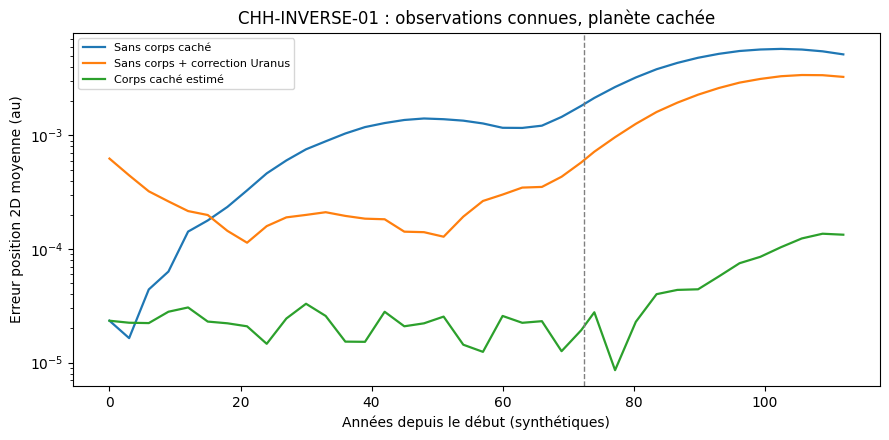

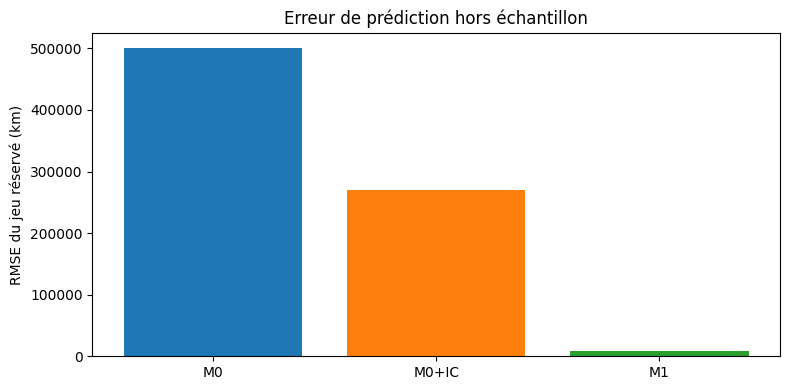

In [8]:
fig,ax=plt.subplots(figsize=(9,4.5))
for label,pred in [('Sans corps caché',m0_prediction),('Sans corps + correction Uranus',m0ic_prediction),('Corps caché estimé',fit_prediction)]:
    # Par date, distance euclidienne moyenne par planète connue.
    dist=np.sqrt(np.mean(np.sum((pred-obs_all)**2,axis=-1),axis=1))
    ax.plot(ALL_T,dist,label=label,lw=1.6)
ax.axvline(72.5,color='gray',ls='--',lw=1)
ax.set_yscale('log');ax.set_xlabel('Années depuis le début (synthétiques)')
ax.set_ylabel('Erreur position 2D moyenne (au)');ax.legend(fontsize=8)
ax.set_title('CHH-INVERSE-01 : observations connues, planète cachée')
plt.tight_layout();plt.show()

fig,ax=plt.subplots(figsize=(8,4))
labels=['M0','M0+IC','M1']
for label,k in zip(labels,comparison):
    ax.bar(label,comparison[k]['test_rmse_km'])
ax.set_ylabel('RMSE du jeu réservé (km)')
ax.set_title('Erreur de prédiction hors échantillon')
plt.tight_layout();plt.show()

## Niveau 4 — Verdict scientifique

1. **Résultat numérique PASS, si les critères pré-déclarés ci-dessus réussissent** : un cinquième corps peut être inféré dans une expérience synthétique où la loi gravitationnelle utilisée pour générer et ajuster les données est la même.
2. **Limites** : un seul objet caché, orbite initialement circulaire coplanaire, états initiaux connus supposés exacts (contrôle Uranus partiel), données synthétiques bien plus simples que de véritables mesures astrométriques, génération et inversion fondées sur la même mécanique newtonienne.
3. **CHH ≠ dérivation** : la composition CHH sert de structure descriptive ; la force utilisée est celle de Newton, non une loi de $S_{\rm cand}$.
4. **Résultat GVH** : aucun paramètre de l'action GVH n'est ajusté, aucune EOM GVH n'est vérifiée, aucune planète réelle inconnue n'est découverte. Le « pouvoir prédictif propre à GVH » reste **BLOCKED**.
5. **Verrou suivant** : retirer les hypothèses orbitales trop favorables, modéliser les incertitudes initiales de tous les corps, tester plusieurs corps cachés/distributions diffuses, puis confronter aux **véritables données réservées** de JPL/Horizons. La comparaison GVH vs GR/Newton n'est possible qu'après EOM GVH et unités SI indépendamment établies.

In [9]:
# Certificat autonome créé aussi lors d'une réexécution dans Colab.
result={
 'notebook':'GVH_CHH_INVERSE_01_Hidden_Planet_Recovery_FAST',
 'date':'2026-11-18',
 'status':'SYNTHETIC_NEWTONIAN_INVERSE_LOCAL_PASS' if all(criteria.values()) else 'SYNTHETIC_NEWTONIAN_INVERSE_TEST_FAILED',
 'scientific_GVH_prediction':'BLOCKED',
 'composition_CHH_not_equal_to_dynamical_derivation':True,
 'real_data_used':False,
 'generator_and_inference_same_physics':True,
 'assumptions':['Newtonian coplanar point masses','single hidden body with initial circular orbit','JPL gravitational parameters only','synthetic initial phases','known initial states assumed exact except Uranus nuisance check','Gaussian synthetic noise','holdout times reserved'],
 'units':{'GM6':'10^6 km^3/s^2','radius':'au','phase':'rad','time':'Julian year','position':'au'},
 'sources':['https://ssd.jpl.nasa.gov/astro_par.html','https://ssd.jpl.nasa.gov/planets/discovery.html','https://ssd.jpl.nasa.gov/planets/eph_export.html'],
 'observations_sha256':observations_sha,
 'sigma_au_per_coordinate':SIGMA_AU,
 'training_years':TRAIN_T.tolist(),'heldout_years':TEST_T.tolist(),
 'seed':SEED,'source_truth_after_fit':truth_eval.tolist(),
 'fit':BEST.tolist(),'multistart':fits,'negative_control_fits':neg_fits,
 'model_comparison':comparison,'holdout_improvement_factor_over_best_null':float(ratio_to_best_null),
 'parameter_errors':param_error,'conditional_1sigma_jacobian':uncertainty,
 'jacobian_condition':condition,'nuisance_Uranus_fit':fit_ic.x.tolist(),
 'negative_control':{'estimated_GM6':float(NEG_BEST[0]),'null_test_rmse_au':neg_null_test,'extra_body_test_rmse_au':neg_fit_test,'test_ratio_extra_over_null':float(neg_fit_test/neg_null_test)},
 'invariant_checks':{'energy_relative_drift':energy_drift,'momentum_absolute_drift':momentum_drift},
 'criteria':criteria,'pass_count':int(sum(criteria.values())),'criterion_count':len(criteria),
 'limitations':'Pas un test sur éphémérides réelles, pas une détection de planète et pas une prédiction GVH.'
}
out=Path('GVH_CHH_INVERSE_01_Hidden_Planet_Recovery_FAST_results.json')
out.write_text(json.dumps(result,ensure_ascii=False,indent=2,allow_nan=False),encoding='utf-8')
print('Certificat:',out.resolve())
print('VERDICT:',result['status'],' | GVH:',result['scientific_GVH_prediction'])
assert all(criteria.values()),'Une ou plusieurs conditions pré-déclarées ont échoué.'

Certificat: /mnt/data/GVH_CHH_INVERSE_01_Hidden_Planet_Recovery_FAST_results.json
VERDICT: SYNTHETIC_NEWTONIAN_INVERSE_LOCAL_PASS  | GVH: BLOCKED
